# How popular were the top most recent Kdramas around the world in the month of September 2026?

## Task 3

**Table of Content**
1. [Collect a list of the new, popular K-dramas](#sec1)
2. [Find the wikipedia page titles for each show](#sec2)
3. [Create the csv: get the wikipedia pageviews data](#sec3)
4. [Create the first graph: tv show pageviews by country](#sec4)
5. [Create the second graph: total views for each show](#sec5)

<h3>Import requirements</h3>

In [227]:
import requests, io
from bs4 import BeautifulSoup
from seleniumbase import Driver
from selenium.webdriver.common.by import By
import re
from mwclient import Site
import time
from mwviews.api import PageviewsClient
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

<h2 id="sec1">1. Collect a list of the new, popular K-dramas</h2>

In [228]:
url = "https://mydramalist.com/search?adv=titles&ty=68&co=3&re=2026,2026&ep=1,16&rt=8.5,10&so=newest&or=desc"

with Driver(browser="firefox") as driver:
    driver.open(url)
    rendered_html = driver.get_page_source()
    soup = BeautifulSoup(rendered_html, "html.parser")
    tvshow_cards = soup.find_all(class_="text-primary title")

print(len(tvshow_cards))

10


In [229]:
print(tvshow_cards[0])

<h6 class="text-primary title"><a href="/795728-four-hands">Four Hands, Two Sonatas</a>
<a class="btn simple btn-manage-list" data-id="795728" data-stats="mylist:795728" rel="nofollow"><span><i class="far fa-plus"></i></span></a>
</h6>


In [230]:
titles = []
for tvshow in tvshow_cards[:10]:
    title_tag = tvshow.find_all("a")
    titles.append(title_tag[0].text)

for i in range(0,10):
    print(f"{i}: {titles[i]}")

0: Four Hands, Two Sonatas
1: A Shop for Killers Season 2
2: Agent Kim Reactivated
3: The Prosecutor's Proposal
4: Teach You a Lesson
5: The WONDERfools
6: The Legend of Kitchen Soldier
7: We Are All Trying Here
8: Yumi's Cells Season 3
9: Bloodhounds Season 2


<h3>Remove season numbers and caps lock to get final show titles</h3>

In [231]:
titles = [str(re.sub(r'season|\d', '', title, flags=re.IGNORECASE)).rstrip() for title in titles]

<h3>The capital letters in WONDERfools will not work with mwclient searching, so remove them</h3>

In [232]:
titles[5] = "The Wonderfools"

In [233]:
for i in range(0,10):
    print(f"{i}: {titles[i]}")

0: Four Hands, Two Sonatas
1: A Shop for Killers
2: Agent Kim Reactivated
3: The Prosecutor's Proposal
4: Teach You a Lesson
5: The Wonderfools
6: The Legend of Kitchen Soldier
7: We Are All Trying Here
8: Yumi's Cells
9: Bloodhounds


<h2 id="sec2">2. Find the wikipedia page titles for each show</h2>

In [234]:
site = Site("en.wikipedia.org")

<h3>Use input to confirm whether the titles lead to the correct wikipedia page with mwclient, not sure how else to confirm than to check</h3>

In [235]:
wikipedia_titles = []

i = 0
for title in titles:
    print(f"{i}: {title}")
    page = site.pages[title]
    text = page.text()
    print(text[:100])
    if "South Korean television series" in text:
        print(">> Title is correct")
        wikipedia_titles.append(title)
    else:
        print("Title is incorrect... trying again")
        title = f"{title} (TV series)"
        time.sleep(2)
        print()
        print(f"{i}: {title} | RETRY")
        page = site.pages[title]
        text = page.text()
        print(text[:100])
        if "South Korean television series" in text:
            print(">> Title + (TV series) is correct")
            wikipedia_titles.append(title)
    print()
    i += 1
    time.sleep(2)

0: Four Hands, Two Sonatas
{{Short description|2026 South Korean television series}}
{{Other uses|Four Hands (disambiguation){{
>> Title is correct

1: A Shop for Killers
{{Short description|2024 South Korean television series}}
{{Distinguish|The Killer's Shopping List}}
>> Title is correct

2: Agent Kim Reactivated
{{Short description|2026 South Korean television series}}
{{Infobox television
| image              
>> Title is correct

3: The Prosecutor's Proposal
{{Short description|2026 South Korean television series}}
{{Infobox television
| image              
>> Title is correct

4: Teach You a Lesson
{{Short description|2026 South Korean television series}}
{{Use mdy dates|date=June 2026}}
{{Infobox
>> Title is correct

5: The Wonderfools
{{Short description|2026 South Korean television series}}
{{Use mdy dates|date=May 2026}}
{{Infobox 
>> Title is correct

6: The Legend of Kitchen Soldier
{{Short description|2026 South Korean television series}}
{{Use mdy dates|date=April 2026}}

In [236]:
for i in range(0,10):
    print(f"{i}: {wikipedia_titles[i]}")

0: Four Hands, Two Sonatas
1: A Shop for Killers
2: Agent Kim Reactivated
3: The Prosecutor's Proposal
4: Teach You a Lesson
5: The Wonderfools
6: The Legend of Kitchen Soldier
7: We Are All Trying Here
8: Yumi's Cells
9: Bloodhounds (TV series)


In [237]:
wikipedia_titles = [re.sub(r'\s', '_', title, flags=re.IGNORECASE) for title in wikipedia_titles]

for i in range(0,10):
    print(f"{i}: {wikipedia_titles[i]}")

0: Four_Hands,_Two_Sonatas
1: A_Shop_for_Killers
2: Agent_Kim_Reactivated
3: The_Prosecutor's_Proposal
4: Teach_You_a_Lesson
5: The_Wonderfools
6: The_Legend_of_Kitchen_Soldier
7: We_Are_All_Trying_Here
8: Yumi's_Cells
9: Bloodhounds_(TV_series)


<h2 id="sec3">3. Create the csv: get the wikipedia pageviews data</h2>

In [220]:
p = PageviewsClient(user_agent="cs315 student (nh107)")

In [221]:
headers = {'User-Agent': 'cs315 (nh107)'}
columns = ['country', 'country_abbr', 'project', 'page_id', 'page_title', 'item_id', 'gbc']

days = [
    "01", "02", "03", "04", "05", "06", "07", "08", "09", "10",
    "11", "12", "13", "14", "15", "16", "17", "18", "19", "20",
    "21", "22", "23", "24", "25", "26", "27", "28", "29", "30"
]

df_list = []
for day in days:
    time.sleep(2)
    url = f"https://analytics.wikimedia.org/published/datasets/country_project_page/2026-09-{day}.tsv"
    response = requests.get(url, headers=headers)
    df = pd.read_csv(io.BytesIO(response.content), names=columns, sep='\t', encoding="utf-8") #when i did stringio it messed up, google says bytesio preserves characters from other languages
    wikis_df = df[df['page_title'].isin(wikipedia_titles)].copy()
    wikis_df["date"] = f"09-{day}-2026"
    df_list.append(wikis_df)

data = pd.concat(df_list, ignore_index=True)

In [222]:
data.head()

,country,country_abbr,project,page_id,page_title,item_id,gbc,date
0,Malaysia,MY,en.wikipedia,75697706,A_Shop_for_Killers,Q123999260,160,09-01-2026
1,Singapore,SG,en.wikipedia,79560156,Teach_You_a_Lesson,Q137844128,129,09-01-2026
2,Germany,DE,de.wikipedia,13931524,"Four_Hands,_Two_Sonatas",Q137271520,236,09-01-2026
3,United States,US,en.wikipedia,79560156,Teach_You_a_Lesson,Q137844128,577,09-01-2026
4,India,IN,en.wikipedia,82034667,"Four_Hands,_Two_Sonatas",Q137271520,1082,09-01-2026


<h3>Save data to csv file</h3>

In [223]:
data.to_csv('top10shows_september_pageviews.csv', index=False)

<h3>Save some df country info</h3>

In [238]:
countries = set(data['country'])
print(countries)

{'Italy', 'Philippines', 'Poland', 'Australia', 'Indonesia', 'United States', 'Brazil', 'India', 'Canada', 'Singapore', 'Japan', 'Thailand', 'United Kingdom', 'Nigeria', 'France', 'Malaysia', 'Romania', 'Germany'}


In [239]:
country_pageviews = data.groupby(['country', 'page_title'], as_index=False)['gbc'].sum()
country_pageviews.head(10)

,country,page_title,gbc
0,Australia,Agent_Kim_Reactivated,1740
1,Australia,"Four_Hands,_Two_Sonatas",4027
2,Australia,Teach_You_a_Lesson,1274
3,Australia,The_Wonderfools,90
4,Brazil,"Four_Hands,_Two_Sonatas",3909
5,Canada,A_Shop_for_Killers,276
6,Canada,Agent_Kim_Reactivated,2220
7,Canada,"Four_Hands,_Two_Sonatas",5047
8,Canada,Teach_You_a_Lesson,2129
9,Canada,The_Wonderfools,431


<h2 id="sec4">4. Create the first graph: total views by country</h2>

In [240]:
graph_df = country_pageviews.groupby("country", as_index=False)["gbc"].sum()
graph_df = graph_df.sort_values("gbc", ascending=False)

graph_df

,country,gbc
17,United States,76856
5,India,48175
6,Indonesia,25794
11,Philippines,23277
9,Malaysia,13147
14,Singapore,10289
8,Japan,10108
2,Canada,10103
16,United Kingdom,9221
0,Australia,7131


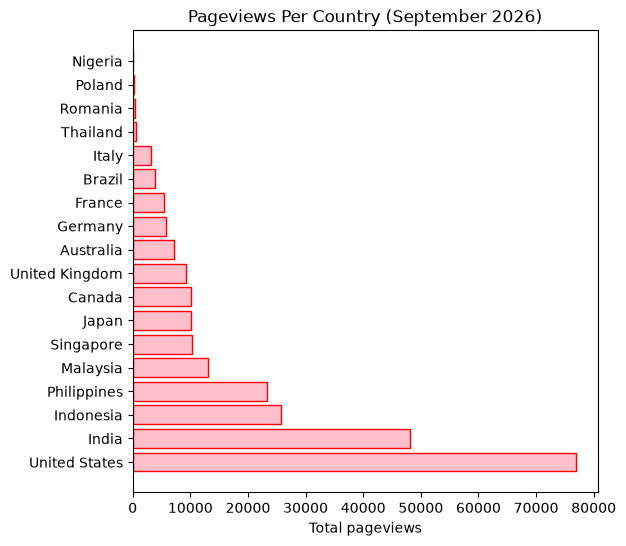

In [241]:
fig, ax = plt.subplots(figsize=(6, 6))

#create  a horizontal bar graph
ax.barh(
    graph_df['country'], 
    width=graph_df['gbc'],
    color="pink",
    edgecolor="red",
)
ax.set_title('Pageviews Per Country (September 2026)')
ax.set_xlabel("Total pageviews")
ax.yaxis.tick_left()

<h2 id="sec5">5. Create the second graph: total views by tv show</h2>

In [242]:
graph_df = country_pageviews.groupby("page_title", as_index=False)["gbc"].sum()
graph_df = graph_df.sort_values("gbc", ascending=False)

graph_df

,page_title,gbc
3,"Four_Hands,_Two_Sonatas",105309
1,Agent_Kim_Reactivated,54615
4,Teach_You_a_Lesson,47148
0,A_Shop_for_Killers,18133
6,The_Wonderfools,13836
2,Bloodhounds_(TV_series),8183
5,The_Legend_of_Kitchen_Soldier,3870
7,We_Are_All_Trying_Here,2492


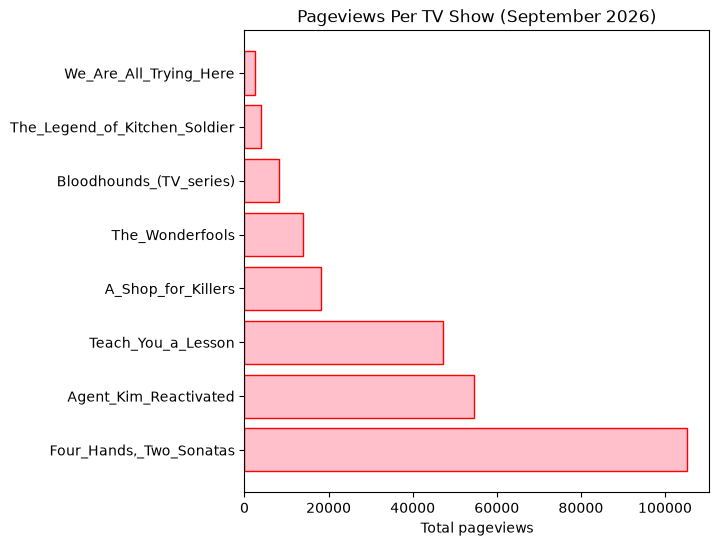

In [243]:
fig, ax = plt.subplots(figsize=(6, 6))

#create  a horizontal bar graph
ax.barh(
    graph_df['page_title'], 
    width=graph_df['gbc'],
    color="pink",
    edgecolor="red",
)
ax.set_title('Pageviews Per TV Show (September 2026)')
ax.set_xlabel("Total pageviews")
ax.yaxis.tick_left()

<h2>Does the popularity in Wikipedia pageviews correlate to the rating for the shows in MyDramaList?</h2>

<p>Just from what I've seen with this task, it seems like there isn't that much of a correlation. This could be because of the TV shows I chose (the way I filtered my search may have been to specific), but it seems like the these popular shows have a large range of wikipedia pageviews, some with over 100,000 and others with less than 10,000.</p>

<p>I'll be interested to see what other people think about this, like what TV shows they used and how their graphs looked in comparison to mine.</p>

<h2>Check why The Prosecutor's Proposal and Yumi's Cells aren't showing any data</h2>

<p>My assumption is that it has to do with the apostraphe, which in the URL, looks like "%27", but when I try this for the title it doesn't work... so, I'm not sure!</p>

<h3>Checking The Prosecutor's Proposal</h3>

In [252]:
url = f"https://analytics.wikimedia.org/published/datasets/country_project_page/2026-09-01.tsv"
response = requests.get(url, headers={'User-Agent': 'cs315 (nh107)'})
df = pd.read_csv(io.BytesIO(response.content), names=['country', 'country_abbr', 'project', 'page_id', 'page_title', 'item_id', 'gbc'], sep='\t', encoding="utf-8") #when i did stringio it messed up, google says bytesio preserves characters from other languages
wikis3_df = df[df['page_title'].astype(str).str.contains("The_Prosecutor")].copy()
wikis3_df["date"] = f"09-01-2026"

wikis3_df

,country,country_abbr,project,page_id,page_title,item_id,gbc,date


In [254]:
url = f"https://analytics.wikimedia.org/published/datasets/country_project_page/2026-09-01.tsv"
response = requests.get(url, headers={'User-Agent': 'cs315 (nh107)'})
df = pd.read_csv(io.BytesIO(response.content), names=['country', 'country_abbr', 'project', 'page_id', 'page_title', 'item_id', 'gbc'], sep='\t', encoding="utf-8") #when i did stringio it messed up, google says bytesio preserves characters from other languages
wikis3_df = df[df['page_title'].astype(str).str.contains("_Proposal")].copy()
wikis3_df["date"] = f"09-01-2026"

wikis3_df

,country,country_abbr,project,page_id,page_title,item_id,gbc,date
28060,Australia,AU,en.wikipedia,864183,Indecent_Proposal,Q603448,94,09-01-2026
29495,United States,US,en.wikipedia,83588228,2026_Michigan_Proposal_1,Q140388405,149,09-01-2026
32427,United States,US,en.wikipedia,665,A_Modest_Proposal,Q264143,325,09-01-2026
42722,United States,US,en.wikipedia,17101981,The_Proposal_(2009_film),Q108586,441,09-01-2026
66616,United Kingdom,GB,en.wikipedia,864183,Indecent_Proposal,Q603448,144,09-01-2026
119728,Canada,CA,en.wikipedia,864183,Indecent_Proposal,Q603448,135,09-01-2026
185709,India,IN,en.wikipedia,864183,Indecent_Proposal,Q603448,194,09-01-2026
202996,United States,US,en.wikipedia,864183,Indecent_Proposal,Q603448,846,09-01-2026
219858,India,IN,en.wikipedia,67590558,Business_Proposal,Q108486931,94,09-01-2026
261391,United States,US,en.wikipedia,67590558,Business_Proposal,Q108486931,156,09-01-2026


<h3>Checking Yumi's Cells</h3>

In [255]:
url = f"https://analytics.wikimedia.org/published/datasets/country_project_page/2026-09-01.tsv"
response = requests.get(url, headers={'User-Agent': 'cs315 (nh107)'})
df = pd.read_csv(io.BytesIO(response.content), names=['country', 'country_abbr', 'project', 'page_id', 'page_title', 'item_id', 'gbc'], sep='\t', encoding="utf-8") #when i did stringio it messed up, google says bytesio preserves characters from other languages
wikis3_df = df[df['page_title'].astype(str).str.contains("Yumi")].copy()
wikis3_df["date"] = f"09-01-2026"

wikis3_df

,country,country_abbr,project,page_id,page_title,item_id,gbc,date
44140,United States,US,en.wikipedia,1158836,Hi_Hi_Puffy_AmiYumi,Q1036094,133,09-01-2026
88122,United States,US,en.wikipedia,70801741,Yumi_Nu,Q112043610,142,09-01-2026


In [256]:
url = f"https://analytics.wikimedia.org/published/datasets/country_project_page/2026-09-01.tsv"
response = requests.get(url, headers={'User-Agent': 'cs315 (nh107)'})
df = pd.read_csv(io.BytesIO(response.content), names=['country', 'country_abbr', 'project', 'page_id', 'page_title', 'item_id', 'gbc'], sep='\t', encoding="utf-8") #when i did stringio it messed up, google says bytesio preserves characters from other languages
wikis3_df = df[df['page_title'].astype(str).str.contains("_Cells")].copy()
wikis3_df["date"] = f"09-01-2026"

wikis3_df

,country,country_abbr,project,page_id,page_title,item_id,gbc,date
216396,United States,US,en.wikipedia,65750909,White_Blood_Cells,Q289539,106,09-01-2026
225421,United States,US,en.wikipedia,54027590,Dead_Cells,Q30639210,155,09-01-2026
